# Entrenamiento

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

# ── Cargar datos ──
X_train = pd.read_csv("csv/X_train.csv")
X_val   = pd.read_csv("csv/X_val.csv")
X_test  = pd.read_csv("csv/X_test.csv")
y_train = pd.read_csv("csv/y_train.csv").squeeze()
y_val   = pd.read_csv("csv/y_val.csv").squeeze()
y_test  = pd.read_csv("csv/y_test.csv").squeeze()

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

Train: (12593, 23) | Val: (2699, 23) | Test: (2699, 23)


In [2]:
def evaluar_modelo(nombre, modelo, X_tr, y_tr, X_v, y_v):

    modelo.fit(X_tr, y_tr)
    pred_tr = modelo.predict(X_tr)
    pred_v  = modelo.predict(X_v)

    metricas = {
        "modelo":    nombre,
        "MAE_train": round(mean_absolute_error(y_tr, pred_tr), 6),
        "MAE_val":   round(mean_absolute_error(y_v,  pred_v),  6),
        "RMSE_train":round(np.sqrt(mean_squared_error(y_tr, pred_tr)), 6),
        "RMSE_val":  round(np.sqrt(mean_squared_error(y_v,  pred_v)),  6),
        "R2_train":  round(r2_score(y_tr, pred_tr), 6),
        "R2_val":    round(r2_score(y_v,  pred_v),  6),
    }

    print(f"\n{'='*50}")
    print(f"  {nombre}")
    print(f"{'='*50}")
    print(f"  MAE   → train: {metricas['MAE_train']}  |  val: {metricas['MAE_val']}")
    print(f"  RMSE  → train: {metricas['RMSE_train']}  |  val: {metricas['RMSE_val']}")
    print(f"  R²    → train: {metricas['R2_train']}  |  val: {metricas['R2_val']}")

    return metricas, modelo

In [3]:
resultados = []

# Linear Regression
m, _ = evaluar_modelo("LinearRegression", LinearRegression(), X_train, y_train, X_val, y_val)
resultados.append(m)

# Ridge
m, _ = evaluar_modelo("Ridge", Ridge(alpha=1.0), X_train, y_train, X_val, y_val)
resultados.append(m)


  LinearRegression
  MAE   → train: 0.021748  |  val: 0.022254
  RMSE  → train: 0.029812  |  val: 0.030859
  R²    → train: 0.522906  |  val: 0.507014

  Ridge
  MAE   → train: 0.021747  |  val: 0.022254
  RMSE  → train: 0.029812  |  val: 0.030859
  R²    → train: 0.522906  |  val: 0.507002


In [4]:
# Random Forest
m, rf = evaluar_modelo(
    "RandomForest",
    RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1),
    X_train, y_train, X_val, y_val
)
resultados.append(m)

# Gradient Boosting
m, gb = evaluar_modelo(
    "GradientBoosting",
    GradientBoostingRegressor(n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42),
    X_train, y_train, X_val, y_val
)
resultados.append(m)

# XGBoost
m, xgb = evaluar_modelo(
    "XGBoost",
    XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.05,
                 subsample=0.8, colsample_bytree=0.8,
                 random_state=42, verbosity=0),
    X_train, y_train, X_val, y_val
)
resultados.append(m)


  RandomForest
  MAE   → train: 0.003851  |  val: 0.005209
  RMSE  → train: 0.006678  |  val: 0.009495
  R²    → train: 0.976057  |  val: 0.953329

  GradientBoosting
  MAE   → train: 0.004416  |  val: 0.005161
  RMSE  → train: 0.007189  |  val: 0.00873
  R²    → train: 0.972259  |  val: 0.960545

  XGBoost
  MAE   → train: 0.003019  |  val: 0.004385
  RMSE  → train: 0.004851  |  val: 0.007468
  R²    → train: 0.987369  |  val: 0.971124


Dispositivo: cuda
  Epoch  10 | Loss train: 0.003747 | Loss val: 0.003425
  Epoch  20 | Loss train: 0.002118 | Loss val: 0.002029
  Epoch  30 | Loss train: 0.001202 | Loss val: 0.001709
  Epoch  40 | Loss train: 0.000724 | Loss val: 0.000923
  Epoch  50 | Loss train: 0.000503 | Loss val: 0.000626
  Epoch  60 | Loss train: 0.000367 | Loss val: 0.000278
  Epoch  70 | Loss train: 0.000298 | Loss val: 0.000293
  Epoch  80 | Loss train: 0.000239 | Loss val: 0.000150
  Epoch  90 | Loss train: 0.000225 | Loss val: 0.000115
  Epoch 100 | Loss train: 0.000211 | Loss val: 0.000108


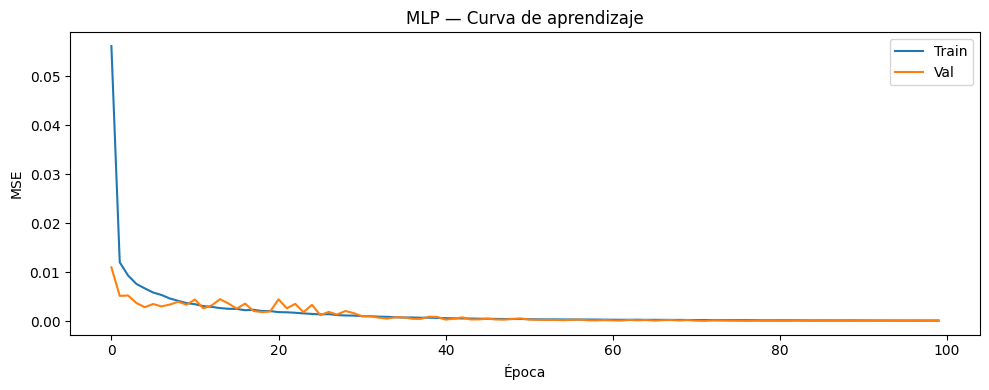


MLP → MAE val: 0.007413 | R² val: 0.947094


In [5]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

device_ml = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device_ml}")

# ── Preparar tensores ──
def to_tensor(X, y=None):
    Xt = torch.tensor(X.values, dtype=torch.float32)
    if y is not None:
        yt = torch.tensor(y.values, dtype=torch.float32).unsqueeze(1)
        return Xt, yt
    return Xt

Xtr, ytr = to_tensor(X_train, y_train)
Xv,  yv  = to_tensor(X_val,   y_val)

train_ds = TensorDataset(Xtr, ytr)
train_dl = DataLoader(train_ds, batch_size=256, shuffle=True)

# ── Arquitectura MLP ──
class MLP(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)

mlp = MLP(X_train.shape[1]).to(device_ml)

optimizer = torch.optim.Adam(mlp.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)
criterion = nn.MSELoss()

# ── Entrenamiento ──
EPOCHS     = 100
historial  = {"train": [], "val": []}
mejor_val  = float("inf")

for epoch in range(1, EPOCHS + 1):

    mlp.train()
    loss_tr = 0
    for Xb, yb in train_dl:
        Xb, yb = Xb.to(device_ml), yb.to(device_ml)
        optimizer.zero_grad()
        loss = criterion(mlp(Xb), yb)
        loss.backward()
        optimizer.step()
        loss_tr += loss.item() * len(Xb)

    loss_tr /= len(train_ds)

    mlp.eval()
    with torch.no_grad():
        pred_v = mlp(Xv.to(device_ml)).cpu().squeeze().numpy()

    loss_v = mean_squared_error(y_val, pred_v)
    scheduler.step(loss_v)

    historial["train"].append(loss_tr)
    historial["val"].append(loss_v)

    if loss_v < mejor_val:
        mejor_val = loss_v
        torch.save(mlp.state_dict(), "csv/mlp_best.pt")

    if epoch % 10 == 0:
        print(f"  Epoch {epoch:3d} | Loss train: {loss_tr:.6f} | Loss val: {loss_v:.6f}")

# ── Curva de aprendizaje ──
plt.figure(figsize=(10, 4))
plt.plot(historial["train"], label="Train")
plt.plot(historial["val"],   label="Val")
plt.title("MLP — Curva de aprendizaje")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.legend()
plt.tight_layout()
plt.show()

# ── Evaluar MLP ──
mlp.load_state_dict(torch.load("csv/mlp_best.pt"))
mlp.eval()
with torch.no_grad():
    pred_tr_mlp = mlp(Xtr.to(device_ml)).cpu().squeeze().numpy()
    pred_v_mlp  = mlp(Xv.to(device_ml)).cpu().squeeze().numpy()

m_mlp = {
    "modelo":    "MLP",
    "MAE_train": round(mean_absolute_error(y_train, pred_tr_mlp), 6),
    "MAE_val":   round(mean_absolute_error(y_val,   pred_v_mlp),  6),
    "RMSE_train":round(np.sqrt(mean_squared_error(y_train, pred_tr_mlp)), 6),
    "RMSE_val":  round(np.sqrt(mean_squared_error(y_val,   pred_v_mlp)),  6),
    "R2_train":  round(r2_score(y_train, pred_tr_mlp), 6),
    "R2_val":    round(r2_score(y_val,   pred_v_mlp),  6),
}
resultados.append(m_mlp)
print(f"\nMLP → MAE val: {m_mlp['MAE_val']} | R² val: {m_mlp['R2_val']}")


COMPARACIÓN DE MODELOS
          modelo  MAE_train  MAE_val  RMSE_val  R2_train   R2_val
         XGBoost   0.003019 0.004385  0.007468  0.987369 0.971124
GradientBoosting   0.004416 0.005161  0.008730  0.972259 0.960545
    RandomForest   0.003851 0.005209  0.009495  0.976057 0.953329
             MLP   0.007303 0.007413  0.010109  0.950159 0.947094
LinearRegression   0.021748 0.022254  0.030859  0.522906 0.507014
           Ridge   0.021747 0.022254  0.030859  0.522906 0.507002


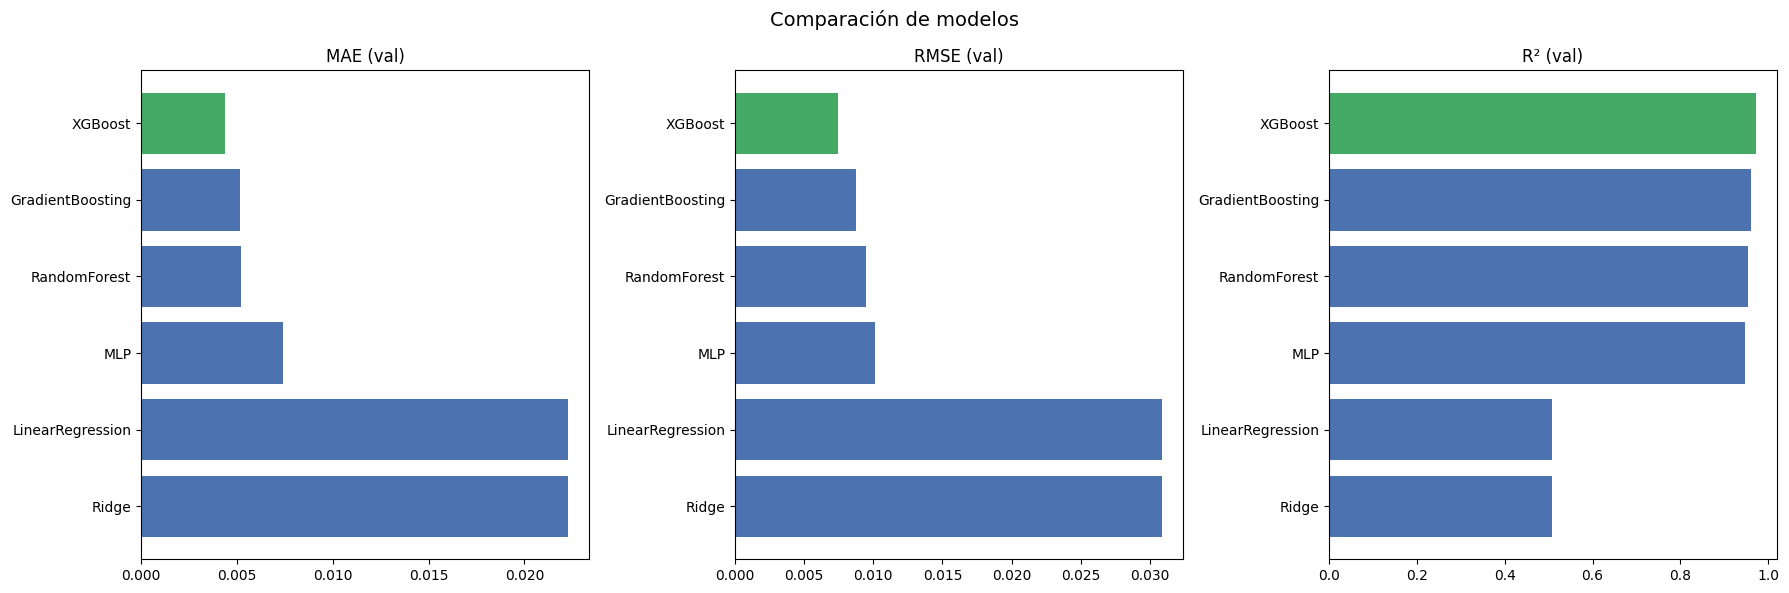


✅ Resultados guardados en csv/resultados_modelos.csv


In [6]:
df_resultados = pd.DataFrame(resultados).sort_values("MAE_val")

print("\n" + "="*70)
print("COMPARACIÓN DE MODELOS")
print("="*70)
print(df_resultados[["modelo", "MAE_train", "MAE_val",
                      "RMSE_val", "R2_train", "R2_val"]].to_string(index=False))

# Gráfica comparativa
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Comparación de modelos", fontsize=14)

for ax, metrica, titulo in zip(
    axes,
    ["MAE_val", "RMSE_val", "R2_val"],
    ["MAE (val)", "RMSE (val)", "R² (val)"]
):
    colores = ["#44AA66" if i == 0 else "#4C72B0"
               for i in range(len(df_resultados))]
    ax.barh(df_resultados["modelo"], df_resultados[metrica], color=colores)
    ax.set_title(titulo)
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

# Guardar resultados
df_resultados.to_csv("csv/resultados_modelos.csv", index=False)
print("\n✅ Resultados guardados en csv/resultados_modelos.csv")

In [7]:
# Reentrenar XGBoost con train+val para maximizar datos
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_train_full = pd.concat([X_train, X_val])
y_train_full = pd.concat([y_train, y_val])

xgb_final = XGBRegressor(
    n_estimators=300, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    random_state=42, verbosity=0
)
xgb_final.fit(X_train_full, y_train_full)

pred_test = xgb_final.predict(X_test)

print("=" * 50)
print("EVALUACIÓN FINAL EN TEST — XGBoost")
print("=" * 50)
print(f"MAE:  {mean_absolute_error(y_test, pred_test):.6f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, pred_test)):.6f}")
print(f"R²:   {r2_score(y_test, pred_test):.6f}")

# Guardar modelo final
import joblib
joblib.dump(xgb_final, "csv/xgb_final.pkl")
print("\n✅ Modelo guardado: csv/xgb_final.pkl")

EVALUACIÓN FINAL EN TEST — XGBoost
MAE:  0.004150
RMSE: 0.006827
R²:   0.975722

✅ Modelo guardado: csv/xgb_final.pkl
